In [60]:
import pandas as pd
import statsmodels.formula.api as smf
import scipy.stats as st
import matplotlib.pyplot as plt
from statsmodels.iolib.summary2 import summary_col as sc
import numpy as np

url = 'https://raw.githubusercontent.com/git-iush/large_family/refs/heads/main/data2.parquet'

In [61]:
df = pd.read_parquet(url)
df.head()

,SERIAL,HHWT,CLUSTER,STRATA,PERNUM,PERWT,NCHILD,SEX,AGE,MARST,...,BLACK,AIAN,API,OTHER,MULTR,HISP,EXPANSION,WELFARE,PRSNINC,YRSEDUC
0,4,4.0,2024000000041,280201,1,4.0,0,2,22,6,...,0,0,1,0,0,0,0,0.0,1000.0,13
1,9,74.0,2024000000091,280301,1,74.0,0,2,18,6,...,1,0,0,0,0,0,0,0.0,5100.0,12
2,12,55.0,2024000000121,160001,1,55.0,0,2,19,6,...,0,0,0,0,0,0,0,0.0,0.0,12
3,15,17.0,2024000000151,120201,1,17.0,0,2,19,6,...,0,0,0,0,0,0,0,0.0,6000.0,12
4,19,71.0,2024000000191,10001,1,71.0,0,2,23,6,...,0,0,0,0,0,0,0,0.0,0.0,13


In [63]:
df.columns

Index(['SERIAL', 'HHWT', 'CLUSTER', 'STRATA', 'PERNUM', 'PERWT', 'NCHILD',
       'SEX', 'AGE', 'MARST', 'HCOVANY', 'HINSCAID', 'EDUCD', 'INCTOT',
       'FTOTINC', 'INCWELFR', 'CONNETICUT', 'MAINE', 'MASSACHUSETTS',
       'NEWHAMPSHIRE', 'RHODEISLAND', 'VERMONT', 'DELAWARE', 'NEWJERSEY',
       'NEWYORK', 'PENNSYLVANIA', 'ILLINOIS', 'INDIANA', 'MICHIGAN', 'OHIO',
       'WISCONSIN', 'IOWA', 'KANSAS', 'MINNESOTA', 'MISSOURI', 'NEBRASKA',
       'NORTHDAKOTA', 'SOUTHDAKOTA', 'VIRGINIA', 'ALABAMA', 'ARKANSAS',
       'GEORGIA', 'LOUISIANA', 'MISSISSIPPI', 'NORTHCAROLINA', 'SOUTHCAROLINA',
       'TEXAS', 'KENTUCKY', 'MARYLAND', 'OKLAHOMA', 'TENNESSEE',
       'WESTVIRGINIA', 'ARIZONA', 'COLORADO', 'IDAHO', 'MONTANA', 'NEVADA',
       'NEWMEXICO', 'UTAH', 'WYOMING', 'CALIFORNIA', 'OREGON', 'WASHINGTON',
       'ALASKA', 'HAWAII', 'DC', 'BLACK', 'AIAN', 'API', 'OTHER', 'MULTR',
       'HISP', 'EXPANSION', 'WELFARE', 'PRSNINC', 'YRSEDUC'],
      dtype='str')

In [66]:
education = df['EDUCD'].unique
education

<bound method Series.unique of 0         71
1         63
2         65
3         63
4         71
          ..
720663    63
720664    26
720665    71
720666    64
720667    61
Name: EDUCD, Length: 720668, dtype: int64>

In [104]:
df['MEDICAID'] = df['HINSCAID'] - 1
df['MEDFARE'] = df['MEDICAID'] * df['WELFARE']

df['MEDICAGE'] = df['MEDICAID'] * df['AGE']
df['WELFAGE'] = df['WELFARE'] * df['AGE']
df['MEDFARAGE'] = df['MEDFARE'] * df['AGE']

df['MEDICAGE2'] = df['MEDICAGE'] ** 2
df['WELFAGE2'] = df['WELFAGE'] ** 2 
df['MEDFARAGE2'] = df['MEDFARAGE'] ** 2

df['FAMINC'] = df['FTOTINC'] - df['INCTOT']
df['PRSNINC2'] = df['PRSNINC'] ** 2
df['FAMINC2'] = df['FAMINC'] ** 2

df['AGE2'] = df['AGE'] ** 2

df['HIGHSCHOOL'] = [1 if i == 63 or i==64 else 0 for i in df['EDUCD']]
df['BACHELORS'] = [1 if i == 101 else 0 for i in df['EDUCD']]
df['ADVANCED'] = [1 if i>=114 else 0 for i in df['EDUCD']]

df['LARGEFAM'] = [1 if i >= 3 else 0 for i in df['NCHILD']]

In [114]:
fd = 'NCHILD ~ MEDICAID + WELFARE + MEDFARE + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARST + CONNETICUT + MAINE + MASSACHUSETTS + NEWHAMPSHIRE + RHODEISLAND + VERMONT + DELAWARE + NEWJERSEY + NEWYORK + PENNSYLVANIA + ILLINOIS + INDIANA + MICHIGAN + OHIO + WISCONSIN + IOWA + KANSAS + MINNESOTA + MISSOURI + NEBRASKA + NORTHDAKOTA + SOUTHDAKOTA + VIRGINIA + ALABAMA + ARKANSAS + GEORGIA + LOUISIANA + MISSISSIPPI + NORTHCAROLINA + SOUTHCAROLINA + TEXAS + KENTUCKY + MARYLAND + OKLAHOMA + TENNESSEE + WESTVIRGINIA + ARIZONA + COLORADO + IDAHO + MONTANA + NEVADA + NEWMEXICO + UTAH + WYOMING + CALIFORNIA + OREGON + WASHINGTON + ALASKA + HAWAII + DC + BLACK + AIAN + API + OTHER + MULTR + HISP + EXPANSION + HIGHSCHOOL + BACHELORS + ADVANCED'
fdres = smf.ols(fd, data=df).fit()

sd = 'NCHILD ~ MEDICAGE + MEDICAGE2 + WELFAGE + WELFAGE2 + MEDFARAGE + MEDFARAGE2 + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARST + CONNETICUT + MAINE + MASSACHUSETTS + NEWHAMPSHIRE + RHODEISLAND + VERMONT + DELAWARE + NEWJERSEY + NEWYORK + PENNSYLVANIA + ILLINOIS + INDIANA + MICHIGAN + OHIO + WISCONSIN + IOWA + KANSAS + MINNESOTA + MISSOURI + NEBRASKA + NORTHDAKOTA + SOUTHDAKOTA + VIRGINIA + ALABAMA + ARKANSAS + GEORGIA + LOUISIANA + MISSISSIPPI + NORTHCAROLINA + SOUTHCAROLINA + TEXAS + KENTUCKY + MARYLAND + OKLAHOMA + TENNESSEE + WESTVIRGINIA + ARIZONA + COLORADO + IDAHO + MONTANA + NEVADA + NEWMEXICO + UTAH + WYOMING + CALIFORNIA + OREGON + WASHINGTON + ALASKA + HAWAII + DC + BLACK + AIAN + API + OTHER + MULTR + HISP + EXPANSION + HIGHSCHOOL + BACHELORS + ADVANCED'
sdres = smf.ols(sd, data=df).fit()

did = 'NCHILD ~ MEDICAID + WELFARE + MEDFARE + MEDICAGE + MEDICAGE2 + WELFAGE + WELFAGE2 + MEDFARAGE + MEDFARAGE2 + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARST + CONNETICUT + MAINE + MASSACHUSETTS + NEWHAMPSHIRE + RHODEISLAND + VERMONT + DELAWARE + NEWJERSEY + NEWYORK + PENNSYLVANIA + ILLINOIS + INDIANA + MICHIGAN + OHIO + WISCONSIN + IOWA + KANSAS + MINNESOTA + MISSOURI + NEBRASKA + NORTHDAKOTA + SOUTHDAKOTA + VIRGINIA + ALABAMA + ARKANSAS + GEORGIA + LOUISIANA + MISSISSIPPI + NORTHCAROLINA + SOUTHCAROLINA + TEXAS + KENTUCKY + MARYLAND + OKLAHOMA + TENNESSEE + WESTVIRGINIA + ARIZONA + COLORADO + IDAHO + MONTANA + NEVADA + NEWMEXICO + UTAH + WYOMING + CALIFORNIA + OREGON + WASHINGTON + ALASKA + HAWAII + DC + BLACK + AIAN + API + OTHER + MULTR + HISP + EXPANSION + HIGHSCHOOL + BACHELORS + ADVANCED'
didres = smf.ols(did, data=df).fit()




In [110]:
log = 'LARGEFAM ~ MEDICAID + WELFARE + MEDFARE + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARST + CONNETICUT + MAINE + MASSACHUSETTS + NEWHAMPSHIRE + RHODEISLAND + VERMONT + DELAWARE + NEWJERSEY + NEWYORK + PENNSYLVANIA + ILLINOIS + INDIANA + MICHIGAN + OHIO + WISCONSIN + IOWA + KANSAS + MINNESOTA + MISSOURI + NEBRASKA + NORTHDAKOTA + SOUTHDAKOTA + VIRGINIA + ALABAMA + ARKANSAS + GEORGIA + LOUISIANA + MISSISSIPPI + NORTHCAROLINA + SOUTHCAROLINA + TEXAS + KENTUCKY + MARYLAND + OKLAHOMA + TENNESSEE + WESTVIRGINIA + ARIZONA + COLORADO + IDAHO + MONTANA + NEVADA + NEWMEXICO + UTAH + WYOMING + CALIFORNIA + OREGON + WASHINGTON + ALASKA + HAWAII + DC + BLACK + AIAN + API + OTHER + MULTR + HISP + EXPANSION + HIGHSCHOOL + BACHELORS + ADVANCED'

logres = smf.logit(log, data=df).fit()

Optimization terminated successfully.
         Current function value: 0.281584
         Iterations 9


In [115]:
print(fdres.summary())

                            OLS Regression Results                            
Dep. Variable:                 NCHILD   R-squared:                       0.329
Model:                            OLS   Adj. R-squared:                  0.329
Method:                 Least Squares   F-statistic:                     4831.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:42:47   Log-Likelihood:            -9.5987e+05
No. Observations:              678476   AIC:                         1.920e+06
Df Residuals:                  678406   BIC:                         1.921e+06
Df Model:                          69                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -1.7335      0.017   -103.766

In [116]:
print(sdres.summary())

                            OLS Regression Results                            
Dep. Variable:                 NCHILD   R-squared:                       0.331
Model:                            OLS   Adj. R-squared:                  0.331
Method:                 Least Squares   F-statistic:                     4654.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:42:51   Log-Likelihood:            -9.5927e+05
No. Observations:              678476   AIC:                         1.919e+06
Df Residuals:                  678403   BIC:                         1.920e+06
Df Model:                          72                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -1.6586      0.017    -98.247

In [117]:
print(didres.summary())

                            OLS Regression Results                            
Dep. Variable:                 NCHILD   R-squared:                       0.332
Model:                            OLS   Adj. R-squared:                  0.332
Method:                 Least Squares   F-statistic:                     4490.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:42:53   Log-Likelihood:            -9.5870e+05
No. Observations:              678476   AIC:                         1.918e+06
Df Residuals:                  678400   BIC:                         1.918e+06
Df Model:                          75                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -1.3952      0.019    -74.166

In [118]:
print(logres.summary())

                           Logit Regression Results                           
Dep. Variable:               LARGEFAM   No. Observations:               678476
Model:                          Logit   Df Residuals:                   678405
Method:                           MLE   Df Model:                           70
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.1945
Time:                        16:42:58   Log-Likelihood:            -1.9105e+05
converged:                       True   LL-Null:                   -2.3719e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       -18.1237      0.129   -140.738      0.000     -18.376     -17.871
MEDICAID          0.7987      0.012     67.854      0.000       0.776       0.822
WELFARE          -0.3123      0.094     

In [122]:
print(df['MEDFARE'].sum())
print(df.shape)



10293.0
(720668, 94)


In [121]:
print(12513/720668)

0.017363057607664


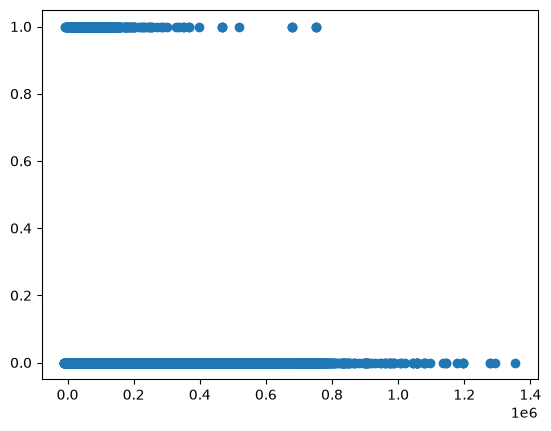

In [124]:
plt.plot(df['PRSNINC'], df['WELFARE'], 'o')
plt.show()